<a href="https://colab.research.google.com/github/missryta/411w8/blob/master/Cryptography.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pycryptodome

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 23.2 MB/s eta 0:00:00


In [ ]:
from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes

# AES key
key = get_random_bytes(16)

# My plaintext messages
messages = [
    b"RYTA",
    b"NKECHI",
    b"ESEMENE"
]

print("AES key:", key.hex())

print("Plaintext messages:")

for message in messages:
    print(message.decode())

AES key: 5be766f621d8f796bf99db49146150a4
Plaintext messages:
RYTA
NKECHI
ESEMENE


In [ ]:
# ECB encryption

from Crypto.Util.Padding import pad

plaintext = b"RYTA"

print("Plaintext:", plaintext.decode())
print("\nECB encryption:")

for i in range(3):
    cipher = AES.new(key, AES.MODE_ECB)
    ciphertext = cipher.encrypt(pad(plaintext, AES.block_size))

    print("Run", i + 1, ":", ciphertext.hex())

Plaintext: RYTA

ECB encryption:
Run 1 : e38d5519b17e2c7aeb6ce1ff7dfc86dd
Run 2 : e38d5519b17e2c7aeb6ce1ff7dfc86dd
Run 3 : e38d5519b17e2c7aeb6ce1ff7dfc86dd


In [ ]:
# CBC encryption with a new IV each time

from Crypto.Util.Padding import pad

plaintext = b"RYTA"

print("Plaintext:", plaintext.decode())
print("\nCBC encryption:")

for i in range(3):
    iv = get_random_bytes(16)

    cipher = AES.new(key, AES.MODE_CBC, iv)
    ciphertext = cipher.encrypt(pad(plaintext, AES.block_size))

    print("Run", i + 1)
    print("IV:        ", iv.hex())
    print("Ciphertext:", ciphertext.hex())

Plaintext: RYTA

CBC encryption:
Run 1
IV:         fcd534476936877472b9741b6aae38ba
Ciphertext: 902fdc2d9c35cf305a696193f32b5a4f
Run 2
IV:         ff0ad39a775e892da0c7112e2331728e
Ciphertext: 7e711a4454461f227560b7d436bf6baa
Run 3
IV:         00746ffe9437e3af8cc787d11747980d
Ciphertext: 8944ab93acd1b297c383e9290bdf479d


In [ ]:
# CBC with the SAME IV reused

from Crypto.Util.Padding import pad

plaintext = b"RYTA"

# Generate ONE IV
iv = get_random_bytes(16)

print("Plaintext:", plaintext.decode())
print("Same IV will be used for both encryptions")
print("IV:", iv.hex())

# First encryption
cipher1 = AES.new(key, AES.MODE_CBC, iv)
ciphertext1 = cipher1.encrypt(pad(plaintext, AES.block_size))

# Second encryption using the SAME IV
cipher2 = AES.new(key, AES.MODE_CBC, iv)
ciphertext2 = cipher2.encrypt(pad(plaintext, AES.block_size))

print("\nEncryption 1:")
print("Ciphertext:", ciphertext1.hex())

print("\nEncryption 2:")
print("Ciphertext:", ciphertext2.hex())

print("\nAre the ciphertexts the same?")
print(ciphertext1 == ciphertext2)

Plaintext: RYTA
Same IV will be used for both encryptions
IV: 7685cd3edc6b75161dbc2f0443a64b05

Encryption 1:
Ciphertext: bc6b5ba98de87ca1e003db94f1281cb2

Encryption 2:
Ciphertext: bc6b5ba98de87ca1e003db94f1281cb2

Are the ciphertexts the same?
True


In [ ]:
# GCM encryption with a new nonce each time

plaintext = b"RYTA"

print("Plaintext:", plaintext.decode())
print("\nGCM encryption:")

for i in range(3):
    nonce = get_random_bytes(12)

    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    ciphertext, tag = cipher.encrypt_and_digest(plaintext)

    print("\nRun", i + 1)
    print("Nonce:     ", nonce.hex())
    print("Ciphertext:", ciphertext.hex())
    print("Tag:       ", tag.hex())

Plaintext: RYTA

GCM encryption:

Run 1
Nonce:      f5eb4b02324b851ee345ce7d
Ciphertext: a744cf48
Tag:        822f662ce50a786a455feb61705e24f3

Run 2
Nonce:      4cde98d64e995fc1d1ba372d
Ciphertext: 16b29518
Tag:        e8a716327834e48b9efe4a181e95106b

Run 3
Nonce:      f4661fc4906f5029f5322952
Ciphertext: 520e0b04
Tag:        d710b8ba5588a7194f33a0719477eb9e


In [ ]:
# GCM with the SAME nonce reused

plaintext = b"RYTA"

# Generate ONE nonce
nonce = get_random_bytes(12)

print("Plaintext:", plaintext.decode())
print("Same nonce will be used for both encryptions")
print("Nonce:", nonce.hex())

# First encryption
cipher1 = AES.new(key, AES.MODE_GCM, nonce=nonce)
ciphertext1, tag1 = cipher1.encrypt_and_digest(plaintext)

# Second encryption using the SAME nonce
cipher2 = AES.new(key, AES.MODE_GCM, nonce=nonce)
ciphertext2, tag2 = cipher2.encrypt_and_digest(plaintext)

print("\nEncryption 1:")
print("Ciphertext:", ciphertext1.hex())
print("Tag:       ", tag1.hex())

print("\nEncryption 2:")
print("Ciphertext:", ciphertext2.hex())
print("Tag:       ", tag2.hex())

print("\nAre the ciphertexts the same?")
print(ciphertext1 == ciphertext2)

print("\nAre the tags the same?")
print(tag1 == tag2)

Plaintext: RYTA
Same nonce will be used for both encryptions
Nonce: 408fb069be2b52fc4d8c297a

Encryption 1:
Ciphertext: c13d5810
Tag:        b3fe96d6258c39eda3cc25f0f4bb2cfb

Encryption 2:
Ciphertext: c13d5810
Tag:        b3fe96d6258c39eda3cc25f0f4bb2cfb

Are the ciphertexts the same?
True

Are the tags the same?
True


In [ ]:
p = 3
q = 5

n = p * q

phi = (p - 1) * (q - 1)

print("p =", p)
print("q =", q)
print("n =", n)
print("phi(n) =", phi)

p = 3
q = 5
n = 15
phi(n) = 8


In [ ]:
e = 3

print("e =", e)

e = 3


In [ ]:
d = 3

print("d =", d)

d = 3


In [ ]:
message = 2

ciphertext = pow(message, e, n)

print("Original message:", message)
print("Encrypted message:", ciphertext)

Original message: 2
Encrypted message: 8


In [ ]:
decrypted = pow(ciphertext, d, n)

print("Encrypted message:", ciphertext)
print("Decrypted message:", decrypted)

Encrypted message: 8
Decrypted message: 2


In [ ]:
pow(message, e, n)

8

In [ ]:
import random

primes = [3, 5, 7, 11, 13]

p = random.choice(primes)
q = random.choice(primes)

while q == p:
    q = random.choice(primes)

print("p =", p)
print("q =", q)

p = 13
q = 7


In [ ]:
n = p * q

print("p =", p)
print("q =", q)
print("n =", n)

p = 13
q = 7
n = 91


In [ ]:
phi = (p - 1) * (q - 1)

print("phi(n) =", phi)

phi(n) = 72


In [ ]:
e = 5

print("e =", e)

e = 5


In [ ]:
d = 29

print("d =", d)

d = 29


In [ ]:
message = 10

ciphertext = pow(message, e, n)

print("Original message:", message)
print("Encrypted message:", ciphertext)

Original message: 10
Encrypted message: 82


In [ ]:
decrypted = pow(ciphertext, d, n)

print("Encrypted message:", ciphertext)
print("Decrypted message:", decrypted)

Encrypted message: 82
Decrypted message: 10


In [1]:
# Diffie-Hellman example

p = 23
g = 5

# Private values
a = 6
b = 15

# Public values
A = pow(g, a, p)
B = pow(g, b, p)

print("Prime p =", p)
print("Generator g =", g)

print("\nPrivate value a =", a)
print("Public value A =", A)

print("\nPrivate value b =", b)
print("Public value B =", B)

Prime p = 23
Generator g = 5

Private value a = 6
Public value A = 8

Private value b = 15
Public value B = 19


In [2]:
# Calculate the shared secret

secret_A = pow(B, a, p)
secret_B = pow(A, b, p)

print("Secret calculated by A =", secret_A)
print("Secret calculated by B =", secret_B)

print("Are the secrets the same?")
print(secret_A == secret_B)

Secret calculated by A = 2
Secret calculated by B = 2
Are the secrets the same?
True


In [3]:
import random

p = 23
g = 5

# Random private values
a = random.randint(2, p - 2)
b = random.randint(2, p - 2)

# Public values
A = pow(g, a, p)
B = pow(g, b, p)

# Shared secrets
secret_A = pow(B, a, p)
secret_B = pow(A, b, p)

print("p =", p)
print("g =", g)

print("Private value a =", a)
print("Public value A =", A)

print("Private value b =", b)
print("Public value B =", B)

print("Shared secret calculated by A =", secret_A)
print("Shared secret calculated by B =", secret_B)

print("Are the secrets the same?")
print(secret_A == secret_B)

p = 23
g = 5
Private value a = 15
Public value A = 19
Private value b = 19
Public value B = 7
Shared secret calculated by A = 14
Shared secret calculated by B = 14
Are the secrets the same?
True


In [4]:
print("Values that can be shared:")
print("p =", p)
print("g =", g)
print("A =", A)
print("B =", B)

print("\nPrivate values:")
print("a =", a)
print("b =", b)

print("\nShared secret:")
print(secret_A)

Values that can be shared:
p = 23
g = 5
A = 19
B = 7

Private values:
a = 15
b = 19

Shared secret:
14


In [5]:
!pip install tinyec

  Preparing metadata (setup.py) ... done
  Created wheel for tinyec: filename=tinyec-0.4.0-py3-none-any.whl size=20969 sha256=2a0df193b35bb2053f2c69dc27007b4197dd0d281dda8e9f10402b8d5fe25c5c
  Stored in directory: /root/.cache/pip/wheels/88/d6/c8/23a7cc21f2291eb7af8c1706a5f46935bd233864e6dbe1bdd3
Successfully built tinyec


In [6]:
from tinyec import registry

# Select an elliptic curve
curve = registry.get_curve('secp256r1')

print("Curve name:", curve.name)
print("Generator point:")
print("x =", curve.g.x)
print("y =", curve.g.y)
print("Curve field prime =", curve.field.p)

Curve name: secp256r1
Generator point:
x = 48439561293906451759052585252797914202762949526041747995844080717082404635286
y = 36134250956749795798585127919587881956611106672985015071877198253568414405109
Curve field prime = 115792089210356248762697446949407573530086143415290314195533631308867097853951


In [7]:
# ECDH: calculate public points

a = 5
b = 7

# Calculate public points
A = a * curve.g
B = b * curve.g

print("Private value a =", a)
print("Private value b =", b)

print("\nPublic point A:")
print("x =", A.x)
print("y =", A.y)

print("\nPublic point B:")
print("x =", B.x)
print("y =", B.y)

Private value a = 5
Private value b = 7

Public point A:
x = 36794669340896883012101473439538929759152396476648692591795318194054580155373
y = 101659946828913883886577915207667153874746613498030835602133042203824767462820

Public point B:
x = 64375483017717711348634889601793836329966447963510648681625681211348943876771
y = 52431391916983504423217627849020916729601969409053901192561322805962577543348


In [8]:
# ECDH: calculate the shared secret points

secret_A = a * B
secret_B = b * A

print("Shared point calculated by A:")
print("x =", secret_A.x)
print("y =", secret_A.y)

print("\nShared point calculated by B:")
print("x =", secret_B.x)
print("y =", secret_B.y)

print("\nAre the shared points the same?")
print(secret_A == secret_B)

Shared point calculated by A:
x = 96592275302800394206739349593735563001905394484977753992044609363860189292826
y = 96040649569972120492280622390866683157690193690540760455799581418342826031573

Shared point calculated by B:
x = 96592275302800394206739349593735563001905394484977753992044609363860189292826
y = 96040649569972120492280622390866683157690193690540760455799581418342826031573

Are the shared points the same?
True


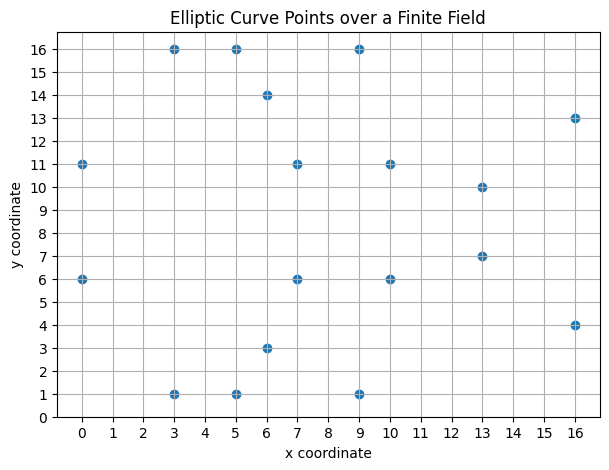

Number of points found: 18


In [9]:
import matplotlib.pyplot as plt

# Small educational elliptic curve:
# y^2 = x^3 + 2x + 2 (mod 17)

p = 17
a_curve = 2
b_curve = 2

points_x = []
points_y = []

# Find points that satisfy the curve equation
for x in range(p):
    for y in range(p):
        if (y**2 - (x**3 + a_curve*x + b_curve)) % p == 0:
            points_x.append(x)
            points_y.append(y)

plt.figure(figsize=(7, 5))
plt.scatter(points_x, points_y)

plt.title("Elliptic Curve Points over a Finite Field")
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.xticks(range(p))
plt.yticks(range(p))
plt.grid(True)

plt.show()

print("Number of points found:", len(points_x))

In [10]:
# Show repeated multiples of a point on the small curve

p = 17
a_curve = 2
b_curve = 2

# Find all points on the curve
points = []

for x in range(p):
    for y in range(p):
        if (y**2 - (x**3 + a_curve*x + b_curve)) % p == 0:
            points.append((x, y))

print("Some points on the curve:")

for point in points[:10]:
    print(point)

print("\nTotal plotted points:", len(points))

Some points on the curve:
(0, 6)
(0, 11)
(3, 1)
(3, 16)
(5, 1)
(5, 16)
(6, 3)
(6, 14)
(7, 6)
(7, 11)

Total plotted points: 18


In [11]:
# Point addition on the small elliptic curve

p = 17
a_curve = 2

def add_points(P, Q):
    if P is None:
        return Q
    if Q is None:
        return P

    x1, y1 = P
    x2, y2 = Q

    # A point and its inverse give the point at infinity
    if x1 == x2 and (y1 + y2) % p == 0:
        return None

    if P != Q:
        slope = ((y2 - y1) * pow(x2 - x1, -1, p)) % p
    else:
        slope = ((3*x1*x1 + a_curve) *
                 pow(2*y1, -1, p)) % p

    x3 = (slope*slope - x1 - x2) % p
    y3 = (slope*(x1 - x3) - y1) % p

    return (x3, y3)


# Starting point
G = (5, 1)

# Calculate G, 2G, 3G, 4G, and 5G
current = None

for k in range(1, 6):
    current = add_points(current, G)
    print(str(k) + "G =", current)

1G = (5, 1)
2G = (6, 3)
3G = (10, 6)
4G = (3, 1)
5G = (9, 16)


In [2]:

!pip install pycryptodome


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 7.9 MB/s eta 0:00:00


In [3]:

from Crypto.PublicKey import RSA
from Crypto.Util.number import bytes_to_long, long_to_bytes

print("PyCryptodome is installed successfully.")


PyCryptodome is installed successfully.


In [4]:

from Crypto.PublicKey import RSA
from Crypto.Util.number import bytes_to_long, long_to_bytes
import secrets

# 1. Generate a small educational RSA key
key = RSA.generate(1024)
n = key.n
e = key.e
d = key.d
k = key.size_in_bytes()

# 2. Create a PKCS#1 v1.5-style encoded message
message = b"HELLO"
padding_length = k - len(message) - 3
padding = bytes(
    [secrets.randbelow(255) + 1 for _ in range(padding_length)]
)
encoded_message = b"\x00\x02" + padding + b"\x00" + message

# 3. Encrypt the encoded message
m = bytes_to_long(encoded_message)
ciphertext = pow(m, e, n)

# 4. Create the padding oracle
def padding_oracle(c):
    decrypted = long_to_bytes(pow(c, d, n), k)

    if not decrypted.startswith(b"\x00\x02"):
        return False

    separator = decrypted.find(b"\x00", 2)
    return separator >= 10

# 5. Ask the oracle questions
print("Original padding valid:", padding_oracle(ciphertext))

modified_ciphertext = (ciphertext + 1) % n
print("Modified ciphertext padding valid:",
      padding_oracle(modified_ciphertext))


Original padding valid: True
Modified ciphertext padding valid: False
